# 04 - Porosity

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_a_foundations/04_porosity.ipynb)

**Part A - Petrophys Curriculum - Foundations**

Porosity is the fraction of rock volume that is pore space, and it carries the
storage term of every volumetric estimate: hydrocarbon volume scales with
$\phi\,(1-S_w)$, and both saturation and permeability estimates are built on it.
This lesson builds porosity three
independent ways (density, neutron, sonic), reconciles them into a **total** porosity,
strips out clay-bound water to get **effective** porosity, and shows the
**hydrocarbon correction** that applies where light HC distorts the raw logs.

We use `petrophys.interpretation.porosity` and `petrophys.interpretation.porosity.hydrocarbon_correction`,
and we reuse the clay volume (Vcl) built in **lesson 03**.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

- Compute **density porosity** from RHOB with the right matrix and fluid densities
  (`density_porosity`, `calculate_phid`).
- Understand **neutron porosity standardization** between matrix calibrations
  (`neutron_porosity`, `standardize_nphi`).
- Compute **sonic porosity** from DTC with the Wyllie time-average equation
  (`sonic_porosity`, `wyllie_time_average`).
- Combine neutron + density into **total porosity** and correct it to **effective
  porosity** using Vcl (`total_porosity`, `effective_porosity`).
- Know how to call the **hydrocarbon correction** of the raw logs
  (`correct_density_hc`, `correct_neutron_hc`) and what input it needs.
- **Compare** the three porosity logs on one overlay and read where they diverge (gas
  crossover, shale) and **classify** the result (`classify_porosity`).

## Why this matters (the physics)

No single tool measures porosity directly; each infers it from a bulk property:

| Log | Equation | Reads porosity **high** when... | Reads **low** when... |
|-----|----------|-------------------------------|------------------------|
| **Density** (RHOB) | $\phi_D=\dfrac{\rho_{ma}-\rho_b}{\rho_{ma}-\rho_{fl}}$ | light HC (low $\rho$) is present | matrix denser than assumed |
| **Neutron** (NPHI) | direct (calibrated) | clay-bound / bound water present | gas (low hydrogen index) |
| **Sonic** (DTC) | $\phi_S=\dfrac{\Delta t-\Delta t_{ma}}{\Delta t_{fl}-\Delta t_{ma}}$ | uncompacted sediments (compaction correction needed) | vugs / fractures: the first arrival bypasses them, so the porosity deficit ($\phi_{total}-\phi_S$, Exercise 3) estimates the secondary porosity |

Because their errors point in *different directions*, the way the three curves
separate is itself diagnostic:

- **Gas effect:** density reads high, neutron reads low -> the classic
  neutron-density **crossover**.
- **Shale:** neutron reads high (clay-bound water), density reads slightly high ->
  they **converge or cross the other way**.

That is why we always look at them together.

### Prerequisites

This lesson assumes **lesson 01** (data access), **lesson 02** (QC), and
especially **lesson 03** (clay volume) - we reuse its Vcl curve to compute
effective porosity. Teaching well: the clastic **30/6-5** (GEOLINK, depths in
metres).

In [2]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys', petrophys.__version__)

petrophys 3.0.0


In [3]:
well = read_las(petrophys.sample('30_6-5'))
print('Well   :', well.name)
print('Samples:', well.n_samples)

for mnem in ['RHOB', 'NPHI', 'DTC', 'GR']:
    print('  has %-5s -> %s' % (mnem, well.has_curve(mnem)))

depth = well.depth
rhob  = well.get('RHOB').data
nphi  = well.get('NPHI').data
dtc   = well.get('DTC').data
print()
print('RHOB mean %.3f g/cc, NPHI mean %.3f v/v, DTC mean %.1f us/ft'
      % (np.nanmean(rhob), np.nanmean(nphi), np.nanmean(dtc)))

Well   : 30/6-5
Samples: 22176
  has RHOB  -> True
  has NPHI  -> True
  has DTC   -> True
  has GR    -> True

RHOB mean 2.176 g/cc, NPHI mean 0.389 v/v, DTC mean 124.3 us/ft


## Step 1 - Density porosity

Density porosity inverts the bulk-density mixing law:

$$ \phi_D = \frac{\rho_{ma} - \rho_b}{\rho_{ma} - \rho_{fl}} $$

The two parameters that matter are the **matrix density** $\rho_{ma}$ (2.65 quartz,
2.71 calcite, 2.87 dolomite) and the **fluid density** $\rho_{fl}$ (1.0 fresh water,
~1.1 brine, ~0.8 oil, ~0.2 gas). 30/6-5 is a sandstone, so we use $\rho_{ma}=2.65$.

`density_porosity(rhob, rhob_matrix, rhob_fluid)` takes explicit numbers;
`calculate_phid(rhob, matrix='sandstone')` looks up the matrix density by name. Both
clip the result to [0, 0.5].

In [4]:
from petrophys.interpretation.porosity import density_porosity, calculate_phid

phid = density_porosity(rhob, rhob_matrix=2.65, rhob_fluid=1.0)
phid_named = calculate_phid(rhob, matrix='sandstone', rhob_fluid=1.0)

print('phi_D (explicit 2.65) mean : %.3f' % np.nanmean(phid))
print('phi_D (matrix=sandstone)   : %.3f' % np.nanmean(phid_named))
print('(identical -> matrix lookup just maps "sandstone" -> 2.65)')

# Sensitivity to the matrix assumption:
for m in ['sandstone', 'limestone', 'dolomite']:
    print('  matrix=%-9s -> mean phi_D = %.3f'
          % (m, np.nanmean(calculate_phid(rhob, matrix=m))))

phi_D (explicit 2.65) mean : 0.286
phi_D (matrix=sandstone)   : 0.286
(identical -> matrix lookup just maps "sandstone" -> 2.65)
  matrix=sandstone -> mean phi_D = 0.286
  matrix=limestone -> mean phi_D = 0.310
  matrix=dolomite  -> mean phi_D = 0.362


Notice how much the matrix assumption moves porosity: picking limestone
(2.71) instead of sandstone raises phi_D by ~2-3 porosity units (2.4 p.u. here)
across the well. Choosing the matrix correctly (from lithology, PEF, or crossplots)
is essential.

## Step 2 - Neutron porosity and standardization

The neutron tool responds to hydrogen index and is recorded against an assumed matrix
calibration - very often **limestone units**, even in a sandstone well. In sandstone,
limestone-calibrated NPHI reads roughly **4 porosity units too low**, so it must be
**standardized** to the true matrix before comparison with density.

- `standardize_nphi(nphi, current_matrix, target_matrix)` applies the matrix shift.
- `neutron_porosity(nphi, nphi_matrix, correction)` applies a matrix-response offset
  and environmental correction, clipping to [0, 0.6].

In [5]:
from petrophys.interpretation.porosity import neutron_porosity, standardize_nphi

# Convert a limestone-calibrated NPHI to the sandstone scale.
nphi_ss = standardize_nphi(nphi, current_matrix='limestone', target_matrix='sandstone')

print('NPHI raw (limestone-cal) mean : %.3f' % np.nanmean(nphi))
print('NPHI standardized -> sandstone: %.3f' % np.nanmean(nphi_ss))
print('shift applied                 : %+.3f v/v' % (np.nanmean(nphi_ss) - np.nanmean(nphi)))


NPHI raw (limestone-cal) mean : 0.389
NPHI standardized -> sandstone: 0.429
shift applied                 : +0.040 v/v


#### Matrix correction

The +0.04 shift is the standard limestone-to-sandstone neutron correction for
this example. Omitting it would make neutron porosity read systematically low
relative to the sandstone-calibrated density response.


> **Which NPHI do I feed downstream?** The 30/6-5 header does not state the neutron's
> calibration matrix. The library treats NPHI as limestone-referenced: the sandstone
> clean line it uses (lesson 03) starts at NPHI = -0.02, the quartz matrix point on a
> limestone scale. For the porosity combination below we nevertheless keep the **raw**
> NPHI. (The simple neutron-density average of lessons 07-09 takes
> `neutron_porosity(NPHI)`, which by default adds 0.02, the quartz matrix offset, not the
> full sandstone shift.) Know what that costs: in clean sandstone a limestone-scale neutron reads about
> 0.04 low against the sandstone density porosity (the shift printed above), so the
> raw-NPHI blend slightly understates porosity and makes the pair look closer to
> crossover than it is. The standardization step above removes that offset when you
> want a sandstone-referenced neutron (see the pitfalls).

## Step 3 - Sonic porosity (Wyllie time-average)

Sonic porosity uses transit time (slowness) via the Wyllie time-average equation:

$$ \phi_S = \frac{\Delta t - \Delta t_{ma}}{\Delta t_{fl} - \Delta t_{ma}} $$

with matrix slowness $\Delta t_{ma}$ (55.5 sandstone, 47.6 limestone, 43.5 dolomite
us/ft) and fluid slowness $\Delta t_{fl}\approx 189$ us/ft. Sonic porosity responds
mainly to **primary** (intergranular) porosity and tends to miss isolated vugs and
fractures; in uncompacted rock it reads high and needs a compaction factor.

`wyllie_time_average(dtc, dtc_matrix, dtc_fluid)` is the raw equation;
`sonic_porosity(dtc, matrix=..., compaction_factor=...)` adds matrix lookup and a
compaction divisor.

In [6]:
from petrophys.interpretation.porosity import sonic_porosity, wyllie_time_average

phis      = sonic_porosity(dtc, matrix='sandstone', dtc_fluid=189.0)
phis_raw  = wyllie_time_average(dtc, dtc_matrix=55.5, dtc_fluid=189.0)

print('phi_S (sonic_porosity)     mean : %.3f' % np.nanmean(phis))
print('phi_S (wyllie_time_average) mean: %.3f' % np.nanmean(phis_raw))


phi_S (sonic_porosity)     mean : 0.406
phi_S (wyllie_time_average) mean: 0.406


#### Compaction setting

With a compaction factor of 1.0 and a sandstone matrix, the two sonic-porosity
forms are identical because both use a 55.5 us/ft matrix transit time.


## Step 4 - Comparing the three porosity logs

Now the key diagnostic plot: density, neutron (raw), and sonic porosity on one track
against depth. Watch for:

- **Neutron-density crossover** (phi_D above phi_N): light hydrocarbon / gas.
- **Neutron above density and both climbing:** shale (clay-bound water inflates
  neutron).
- **Sonic diverging high:** uncompacted intervals (compaction correction needed).
- **Sonic diverging low:** secondary porosity (vugs/fractures) that the first
  arrival bypasses.

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:834: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:834: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


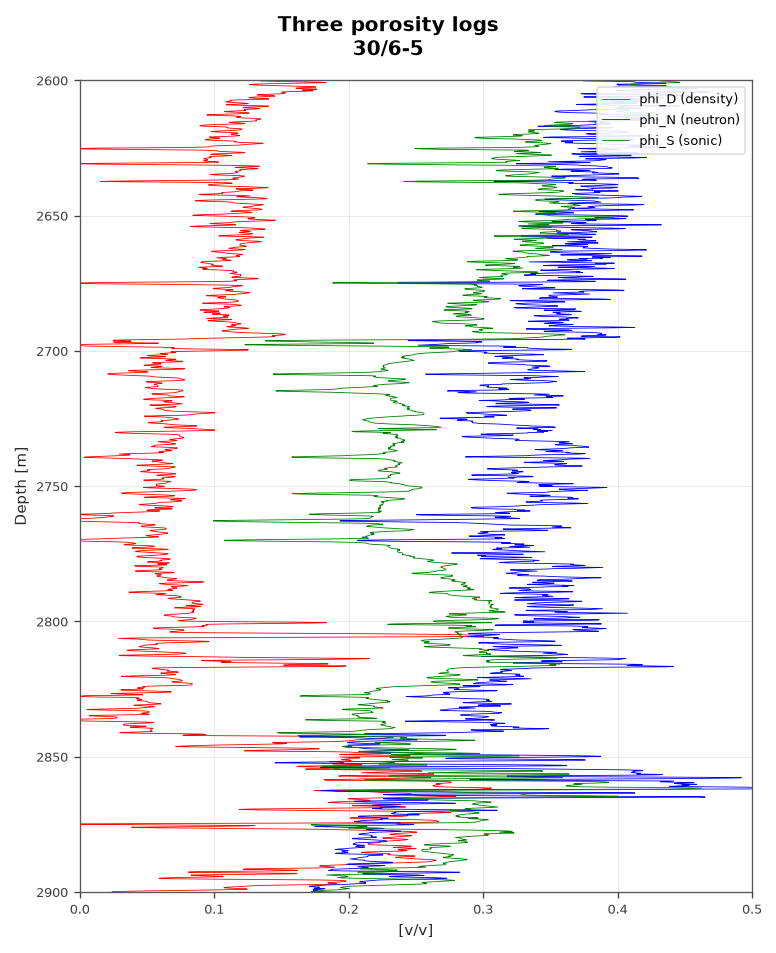

Window means: phi_D=0.105  phi_N=0.328  phi_S=0.278


In [7]:
from petrophys.visualization import LogPlot

top, base = 2600.0, 2900.0
sel = (depth >= top) & (depth <= base)

# Attach the computed porosity logs so LogPlot can render them.
well.add_curve('PHID', phid, unit='v/v', description='Density porosity')
well.add_curve('PHIS', phis, unit='v/v', description='Sonic porosity')

lp = LogPlot(well, figsize=(6.5, 8))
lp.create_figure(n_tracks=1)
lp.add_curve(0, 'PHID', color='red', xlim=(0, 0.5), label='phi_D (density)')
lp.add_curve(0, 'NPHI', color='blue', xlim=(0, 0.5), label='phi_N (neutron)')
lp.add_curve(0, 'PHIS', color='green', xlim=(0, 0.5), label='phi_S (sonic)')
lp.set_depth_range(top, base)
lp.add_title('Three porosity logs')
lp.show()

print('Window means: phi_D=%.3f  phi_N=%.3f  phi_S=%.3f'
      % (np.nanmean(phid[sel]), np.nanmean(nphi[sel]), np.nanmean(phis[sel])))

### Where do they diverge? (gas vs shale)

We can flag the two regimes quantitatively. `detect_gas_effect` (in the total-porosity
module) marks samples where density porosity exceeds neutron by more than a threshold
- the gas signature.

To be honest about this well: 30/6-5 shows almost no real gas crossover (about 0.4%
of samples, only ~12 points in this window), and it has no flushed-zone saturation
curve, so Step 7 shows the HC-correction calls without running them; the bundled well 25_5-1 carries a real crossover
cluster (~3018-3045 m) for readers who want a genuine example.

In [8]:
from petrophys.interpretation.porosity.total_porosity import detect_gas_effect

gas_flag = detect_gas_effect(nphi, phid, threshold=0.05)
sep = phid - nphi   # positive -> density>neutron (gas-like); negative -> shale-like

finite = np.isfinite(sep)
print('Neutron-density separation (phi_D - phi_N):')
print('  gas-like  (phi_D > phi_N + 0.05): %6d samples (%.1f%%)'
      % (gas_flag[finite].sum(), 100.0 * gas_flag[finite].sum() / finite.sum()))
print('  shale-like(phi_N > phi_D)       : %6d samples (%.1f%%)'
      % ((sep < 0).sum(), 100.0 * (sep[finite] < 0).sum() / finite.sum()))


Neutron-density separation (phi_D - phi_N):
  gas-like  (phi_D > phi_N + 0.05):     74 samples (0.4%)
  shale-like(phi_N > phi_D)       :  16452 samples (94.5%)


#### Interpreting neutron-density separation

Positive density-neutron separation identifies candidate gas-affected samples,
but it is not proof of hydrocarbons without supporting resistivity and hole-
quality evidence. Strong negative separation is more consistent with clay-rich,
low-quality rock.


## Step 5 - Total porosity

`total_porosity(nphi, phi_d, method='adaptive')` combines neutron and density into a
single total porosity. The **adaptive** rule (default) is physically motivated:

- where the logs cross over (phi_D > phi_N + 0.05, the **gas** signature), it takes
  the root-mean-square $\sqrt{(\phi_D^2 + \phi_N^2)/2}$ (Gaymard and Poupon, 1968),
  which balances the density reading too high against the neutron reading too low
  (a negative neutron counts as 0); `gas_method='density'` takes density porosity
  there instead;
- otherwise it uses the shale-tolerant weighted average $0.6\,\phi_D + 0.4\,\phi_N$.

The root-mean-square is a gas-zone approximation. `pp.interpret` applies it in
crossover only with `hc_type='gas'`; with its default `hc_type='oil'` it takes
density porosity there. Simpler `average` and `rms` methods are also available.

In [9]:
from petrophys.interpretation.porosity import total_porosity

phit_adaptive = total_porosity(nphi, phid, method='adaptive')
phit_average  = total_porosity(nphi, phid, method='average')
phit_rms      = total_porosity(nphi, phid, method='rms')

print('Total porosity (whole well) by method:')
print('  adaptive : %.3f' % np.nanmean(phit_adaptive))
print('  average  : %.3f' % np.nanmean(phit_average))
print('  rms      : %.3f' % np.nanmean(phit_rms))

phit = phit_adaptive   # use adaptive downstream

Total porosity (whole well) by method:
  adaptive : 0.332
  average  : 0.315
  rms      : 0.330


## Step 6 - Effective porosity (reusing Vcl from lesson 03)

**Total** porosity includes clay-bound water, which is immovable and does not
contribute to flow. **Effective** porosity removes it:

$$ \phi_e = \phi_t - V_{cl}\cdot\phi_{clay} $$

where $\phi_{clay}$ is the porosity of pure clay (~0.15 by default). The library
clips the result to $[0,\ \min(\phi_t,\ 1-V_{cl})]$, so high-Vcl rock cannot go
negative. This is the
number that goes into net-pay and hydrocarbon volume calculations. We first rebuild
the Vcl curve exactly as in lesson 03, then call `effective_porosity`.

In [10]:
from petrophys.interpretation.clay_volume import calculate_vcl
from petrophys.interpretation.porosity import effective_porosity, calculate_phie

# Rebuild Vcl (lesson 03): neutron-density-primary combine, sandstone matrix.
vcl_res = calculate_vcl(well, gr_method='larionov_older', matrix='sandstone',
                        combine='auto')
vcl = vcl_res.vcl
print('Vcl (from lesson 03) mean : %.3f' % np.nanmean(vcl))

phie = effective_porosity(phit, vcl, phi_clay=0.15)
phie_alias = calculate_phie(phit, vcl, phi_clay=0.15)  # same thing
print('Total porosity     mean : %.3f' % np.nanmean(phit))
print('Effective porosity mean : %.3f' % np.nanmean(phie))
print('Clay-bound water   mean : %.3f v/v' % (np.nanmean(phit) - np.nanmean(phie)))

Vcl (from lesson 03) mean : 0.308
Total porosity     mean : 0.332
Effective porosity mean : 0.282
Clay-bound water   mean : 0.050 v/v


[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:834: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:834: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


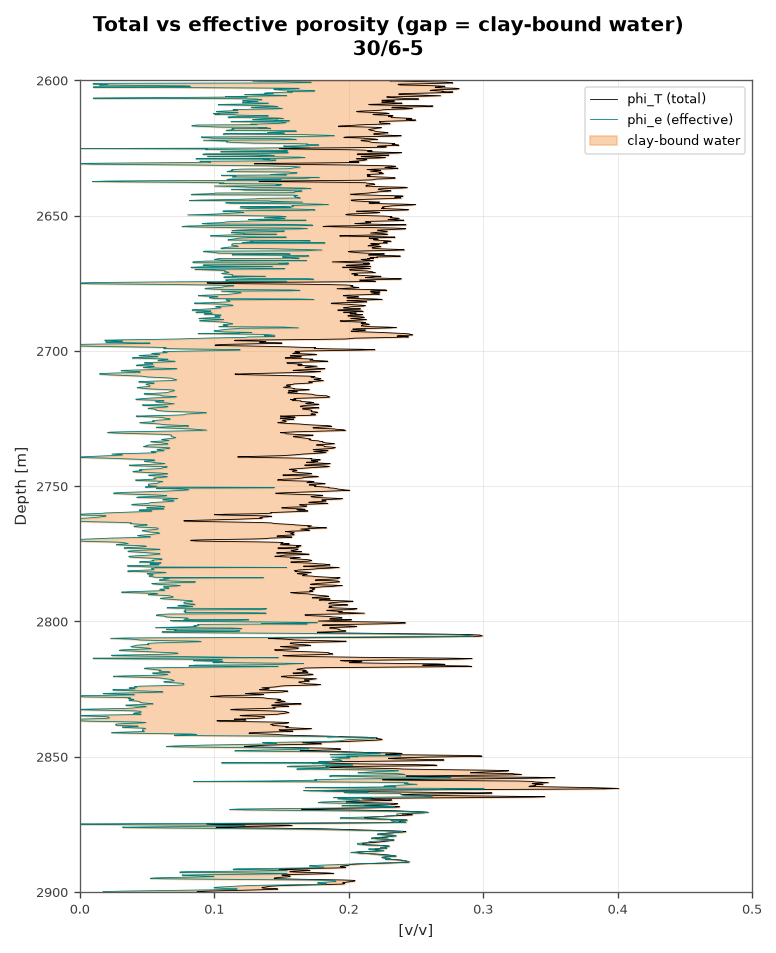

In [11]:
# Total vs effective vs clay, over the window, via the library LogPlot.
from petrophys.visualization import LogPlot

well.add_curve('PHIT', phit, unit='v/v', description='Total porosity')
well.add_curve('PHIE', phie, unit='v/v', description='Effective porosity')

lp = LogPlot(well, figsize=(6.5, 8))
lp.create_figure(n_tracks=1)
lp.add_curve(0, 'PHIT', color='black', xlim=(0, 0.5), label='phi_T (total)')
lp.add_curve(0, 'PHIE', color='teal', xlim=(0, 0.5), label='phi_e (effective)')
# Shade the clay-bound-water gap (phi_e -> phi_T) on the library axis.
lp.axes[0].fill_betweenx(depth[sel], phie[sel], phit[sel],
                         color='sandybrown', alpha=0.5, label='clay-bound water')
lp.axes[0].legend(fontsize=8, loc='upper right')
lp.set_depth_range(top, base)
lp.add_title('Total vs effective porosity (gap = clay-bound water)')
lp.show()

## Step 7 - Hydrocarbon correction

Light hydrocarbon (especially **gas**) has a low density and a low hydrogen index, so
it makes the density log read **too porous** and the neutron log read **too tight**.
Where gas is present the raw logs are corrected before porosity is recomputed.

The correction scales with the hydrocarbon left in the flushed zone, `1 - Sxo`, so it
needs a **flushed-zone water saturation** curve, which 30/6-5 does not carry. With one
(`SXO`, from a micro-resistivity log and the saturation lessons), the calls are:

```python
from petrophys.interpretation.porosity.hydrocarbon_correction import (
    correct_density_hc, correct_neutron_hc, apply_hc_correction)

rhob_hc = correct_density_hc(rhob, phid, sxo, rhob_fluid=1.0, hc_type="gas",
                             vcl=vcl, rho_ma=2.65, rho_cl=2.45)
nphi_hc = correct_neutron_hc(nphi, phid, sxo, hc_type="gas", vcl=vcl, phi_cl=0.15)
hc = apply_hc_correction(well, hc_type="gas", vcl=vcl)   # reads SXO from the well
```

Apply it only where the logs show gas (neutron-density crossover): a flat Sxo applied
to the whole well moves NPHI everywhere, not just in the gas zones. In
`pp.interpret`, `apply_hc_correction=True` runs it before saturation when the well
has an `SXO` curve, and the porosity step then reads `NPHI_HC` and `RHOB_HC`; without
one the step is skipped with a warning.

## Step 8 - Classifying porosity

`classify_porosity` bins porosity into reservoir-quality categories:

- `EXCELLENT` : > 20%
- `GOOD`      : 12-20%
- `FAIR`      : 6-12%
- `POOR`      : <= 6%

We classify the **effective** porosity, since that is the flow-relevant number. The
whole-well split is dominated by the shallow, poorly consolidated section above the
reservoir, where very high apparent porosity says nothing about reservoir quality. So
we also classify the Brent Group reservoir window, 2841-2958 m (Ness and Etive
formations), which is the interval an interpreter would actually report.

In [12]:
from petrophys.interpretation.porosity import classify_porosity

labels = classify_porosity(phie)
label_str = np.array([str(x).split('.')[-1] if x is not None else 'NaN' for x in labels])

order = ['EXCELLENT', 'GOOD', 'FAIR', 'POOR']
finite = np.isfinite(phie)
brent = (depth >= 2841.0) & (depth <= 2958.0)
for title, mask in [('whole well', finite), ('Brent Group 2841-2958 m', finite & brent)]:
    cats, counts = np.unique(label_str[mask], return_counts=True)
    lookup = dict(zip(cats, counts))
    print('Effective-porosity reservoir-quality split (%s):' % title)
    for c in order:
        n = int(lookup.get(c, 0))
        print('  %-10s : %6d samples (%.1f%%)' % (c, n, 100.0 * n / mask.sum()))

Effective-porosity reservoir-quality split (whole well):
  EXCELLENT  :  13844 samples (62.4%)
  GOOD       :   2070 samples (9.3%)
  FAIR       :   2326 samples (10.5%)
  POOR       :   3936 samples (17.7%)
Effective-porosity reservoir-quality split (Brent Group 2841-2958 m):
  EXCELLENT  :    227 samples (29.6%)
  GOOD       :    296 samples (38.5%)
  FAIR       :    104 samples (13.5%)
  POOR       :    141 samples (18.4%)


## Pitfalls and parameter choices

- **Matrix density / slowness is the biggest lever.** Sandstone vs limestone shifts
  porosity by several units. Set it from lithology, PEF, or crossplots - never assume.
- **Standardize the neutron log** to the true matrix before comparing with density,
  or the pair will look artificially crossed-over or converged.
- **Gas crossover is signal, not noise.** The `adaptive` total-porosity rule and the
  HC correction both exploit it; do not "average it away".
- **Total vs effective.** Report effective porosity for pay and volumetrics; total
  porosity for saturation modelling (which needs the clay-bound water).
- **Sonic misses secondary porosity.** In vuggy / fractured rock, phi_S < phi_D; the
  difference estimates secondary porosity.
- **HC correction needs Sxo.** 30/6-5 has no `SXO` curve, so Step 7 only shows the
  calls; in practice Sxo comes from a micro-resistivity log through a flushed-zone
  saturation model.

## Recap

- Built porosity three independent ways: **density** (`density_porosity`), **neutron**
  (raw plus `standardize_nphi`), and **sonic** (`sonic_porosity` / Wyllie).
- Overlaid them and read the divergences: neutron-density **crossover = gas**,
  neutron-over-density **= shale**.
- Combined neutron + density into **total porosity** (`total_porosity`, adaptive) and
  stripped clay-bound water into **effective porosity** (`effective_porosity`) using
  the Vcl from lesson 03.
- Saw how the **gas HC correction** (`correct_density_hc`, `correct_neutron_hc`) is
  called: it needs a flushed-zone Sxo curve and belongs only in flagged gas zones.
- Classified effective porosity into reservoir-quality bins (`classify_porosity`).

## Try it yourself

> **Exercise 1.** Recompute density porosity with `rhob_fluid=1.1` (brine) instead of
> 1.0. How many porosity units does the whole-well mean change, and why?
>
> **Exercise 2.** Call `correct_density_hc` with one assumed Sxo value (for example
> `sxo=0.8`; the argument accepts a number), once with `hc_type='gas'` and once with
> `hc_type='oil'`, and compare the corrected RHOB. Which fluid perturbs the logs more, and why?
>
> **Exercise 3.** Compute `secondary_porosity(phis, phit)` (from the sonic module) and
> plot it. Where in the well does sonic under-read total porosity?

## What's next

With clay volume and porosity in hand, the next foundation is **lithology**: which
minerals make up the rock matrix. Continue with **lesson 05 - Lithology and the
multi-mineral solver** (`05_lithology_and_mineral_solver.ipynb`), which uses
neutron-density and PEF crossplots to solve for mineral volumes instead of assuming a
single matrix density. Lesson 06 then covers formation water and temperature, and
lesson 07 turns resistivity into water saturation using the effective porosity and
Vcl produced here.